# 后量子密码与迁移 · ML-KEM 与 ML-DSA 实际调用

QuantumBridge / 量子安全 / 中文可执行案例

**执行状态：仅本地运行；未提交夸父真机；新增云任务 0。**

面向了解 Python 的读者：完成建模、检查中间结果、运行原生电路或明确标记的经典密码步骤，并与独立基线核对。

**范围边界：** 调用实际密码实现不等于 FIPS 140 模块认证、完整系统迁移或所有 PQC 候选支持。公钥 DER 尺寸包含容器开销；不把 SPKI 尺寸误当原始公钥长度。不包含 UOV/SNOVA 插件。

## 1. 原理与计算对象

后量子密码在经典计算机上运行。本例调用已安装 OpenSSL 的 ML-KEM-768 密钥封装与 ML-DSA-65 签名，不自行实现格密码。
ML-KEM 接收方生成密钥；发送方用公钥封装得到公开密文和共享秘密，接收方解封装得到相同秘密。密文被修改时，隐式拒绝通常返回不同秘密而不是命令报错，因此检查的是秘密不匹配，不能把返回码 0 当成篡改通过。

ML-DSA 对合成迁移清单签名，用公钥验签，再修改清单验证拒绝。全部密钥与共享秘密只放在仅本人可访问的临时目录，完成后删除；结果只记录成功标志和公开尺寸。OpenSSL 正常随机源用于密钥与封装，没有设置测试熵或固定密码种子。

## 2. 实现步骤

1. 确认本地 OpenSSL 支持两个算法；缺少支持时明确失败，不生成模拟密码输出。
2. 在 0700 临时目录生成 KEM 密钥，公钥封装、私钥解封装并比较秘密。
3. 修改密文，检查解封装秘密不同的隐式拒绝行为。
4. 生成 ML-DSA-65 密钥，对合成清单签名并验签。
5. 修改清单验证拒绝；记录命令状态、尺寸及临时目录删除结果。

## 3. 环境与可复现参数

依赖本仓库、NumPy、Matplotlib、Jupyter；安全案例还使用已安装的 OpenSSL / cryptography。模型和电路不调用 Qiskit 或 PennyLane。Notebook 保留真实执行输出，Python 解释器版本会在下方打印。

In [1]:
import os, sys, json
get_ipython().run_line_magic('matplotlib', 'inline')
from pathlib import Path
root = next((p for p in [Path(os.environ.get("QB_REPO_ROOT", ".")).resolve(), *Path.cwd().resolve().parents] if (p/"quantumbridge").is_dir() and (p/"scripts").is_dir()), None)
if root is None:
    raise RuntimeError("Run from the QuantumBridge checkout or set QB_REPO_ROOT.")
sys.path.insert(0, str(root)); sys.path.insert(0, str(root/"scripts"))
from IPython.display import display, HTML
from application_notebook_support import STYLE, show_json, intermediate_tables, plot_intermediate, show_measurements
from quantumbridge.applications.common import run_local_case
display(HTML(STYLE))
SHOTS, SEED = 1024, 20261023
print("Execution: LOCAL ONLY | cloud submissions: 0 | shots per circuit:", SHOTS)

print(sys.version)
import copy
import hashlib
import hmac
import json
import os
from pathlib import Path
import shutil
import subprocess
import tempfile
import numpy as np
from quantumbridge.core import Circuit
from quantumbridge.devices import StatevectorDevice
from quantumbridge.finance.kernels import labels
from quantumbridge.applications.common import ApplicationCase

Execution: LOCAL ONLY | cloud submissions: 0 | shots per circuit: 1024
3.12.6 (v3.12.6:a4a2d2b0d85, Sep  6 2024, 16:08:03) [Clang 13.0.0 (clang-1300.0.29.30)]


## 4. 完整应用建模代码

以下是本案例实际执行的应用函数，不是伪代码。底层电路、映射、演化与采样复用仓库原生接口；优化类的共享辅助函数也位于 `quantumbridge/applications/common.py`。

In [2]:
def pqc_case():
    executable = shutil.which("openssl")
    if not executable:
        raise RuntimeError(
            "OpenSSL with ML-KEM-768 and ML-DSA-65 is required; no simulated fallback."
        )
    version = subprocess.run(
        [executable, "version"], capture_output=True, text=True, check=True, timeout=20
    ).stdout.strip()
    with tempfile.TemporaryDirectory(prefix="qb-pqc-") as directory:
        root = Path(directory)
        root.chmod(0o700)
        commands = []

        def run(*arguments, valid=True):
            result = subprocess.run(
                [executable, *arguments], cwd=root, capture_output=True, timeout=20
            )
            for path in root.iterdir():
                path.chmod(0o600)
            commands.append(
                {"arguments": " ".join(arguments), "returncode": result.returncode}
            )
            if valid and result.returncode:
                raise RuntimeError(
                    "OpenSSL operation failed; verify local provider and algorithm support."
                )
            return result.returncode

        run("genpkey", "-algorithm", "ML-KEM-768", "-out", "kem-private.pem")
        run("pkey", "-in", "kem-private.pem", "-pubout", "-out", "kem-public.pem")
        run(
            "pkey",
            "-in",
            "kem-private.pem",
            "-pubout",
            "-outform",
            "DER",
            "-out",
            "kem-public.der",
        )
        run(
            "pkeyutl",
            "-encap",
            "-pubin",
            "-inkey",
            "kem-public.pem",
            "-out",
            "ciphertext.bin",
            "-secret",
            "sender.bin",
        )
        run(
            "pkeyutl",
            "-decap",
            "-inkey",
            "kem-private.pem",
            "-in",
            "ciphertext.bin",
            "-secret",
            "receiver.bin",
        )
        sender, receiver = (
            (root / "sender.bin").read_bytes(),
            (root / "receiver.bin").read_bytes(),
        )
        ciphertext = (root / "ciphertext.bin").read_bytes()
        changed = bytes([ciphertext[0] ^ 1]) + ciphertext[1:]
        (root / "changed.bin").write_bytes(changed)
        run(
            "pkeyutl",
            "-decap",
            "-inkey",
            "kem-private.pem",
            "-in",
            "changed.bin",
            "-secret",
            "changed-secret.bin",
        )
        implicit_rejection = not hmac.compare_digest(
            sender, (root / "changed-secret.bin").read_bytes()
        )
        (root / "message.bin").write_bytes(
            b"QuantumBridge synthetic migration manifest v1"
        )
        run("genpkey", "-algorithm", "ML-DSA-65", "-out", "signature-private.pem")
        run(
            "pkey",
            "-in",
            "signature-private.pem",
            "-pubout",
            "-out",
            "signature-public.pem",
        )
        run(
            "pkeyutl",
            "-sign",
            "-inkey",
            "signature-private.pem",
            "-in",
            "message.bin",
            "-out",
            "signature.bin",
        )
        valid_signature = (
            run(
                "pkeyutl",
                "-verify",
                "-pubin",
                "-inkey",
                "signature-public.pem",
                "-in",
                "message.bin",
                "-sigfile",
                "signature.bin",
            )
            == 0
        )
        (root / "message.bin").write_bytes(
            b"QuantumBridge altered migration manifest v1"
        )
        rejected_signature = (
            run(
                "pkeyutl",
                "-verify",
                "-pubin",
                "-inkey",
                "signature-public.pem",
                "-in",
                "message.bin",
                "-sigfile",
                "signature.bin",
                valid=False,
            )
            != 0
        )
        sizes = {
            "kem_ciphertext_bytes": len(ciphertext),
            "shared_secret_bytes": len(sender),
            "kem_public_spki_der_bytes": (root / "kem-public.der").stat().st_size,
            "mldsa65_signature_bytes": (root / "signature.bin").stat().st_size,
        }
        matched = hmac.compare_digest(sender, receiver)
    return ApplicationCase(
        "pqc",
        "security",
        "Actual ML-KEM-768 and ML-DSA-65 library round trips",
        {
            "implementation": version,
            "kem": "ML-KEM-768",
            "signature": "ML-DSA-65",
            "execution": "classical OpenSSL provider; not a quantum computer",
        },
        {
            "operation_log": commands,
            "public_sizes": sizes,
            "chart_rows": [
                {"label": key, "value": value} for key, value in sizes.items()
            ],
            "chart_units": "Bytes",
            "chart_title": "Actual local algorithm / container sizes",
        },
        {
            "kem_ciphertext_bytes": 1088,
            "shared_secret_bytes": 32,
            "mldsa65_signature_bytes": 3309,
        },
        {},
        outputs={
            **sizes,
            "shared_secrets_equal": matched,
            "tampered_kem_implicit_rejection": implicit_rejection,
            "valid_signature_accepted": valid_signature,
            "altered_message_rejected": rejected_signature,
            "private_keys_exported": False,
            "temporary_directory_removed": not root.exists(),
            "certification": "not a FIPS module certification or completed migration",
        },
    )


In [3]:
case = pqc_case()
show_json(case.inputs)

## 5. 中间结果与效果

下方完整列出模型候选、优化轨迹或物理中间量。图中的 exact / classical 是经典计算基线，不冒充量子实验。图表使用英文坐标避免本机中文字体缺失，解释与表格保留中文。

arguments,returncode
genpkey -algorithm ML-KEM-768 -out kem-private.pem,0
pkey -in kem-private.pem -pubout -out kem-public.pem,0
pkey -in kem-private.pem -pubout -outform DER -out kem-public.der,0
pkeyutl -encap -pubin -inkey kem-public.pem -out ciphertext.bin -secret sender.bin,0
pkeyutl -decap -inkey kem-private.pem -in ciphertext.bin -secret receiver.bin,0
pkeyutl -decap -inkey kem-private.pem -in changed.bin -secret changed-secret.bin,0
genpkey -algorithm ML-DSA-65 -out signature-private.pem,0
pkey -in signature-private.pem -pubout -out signature-public.pem,0
pkeyutl -sign -inkey signature-private.pem -in message.bin -out signature.bin,0
pkeyutl -verify -pubin -inkey signature-public.pem -in message.bin -sigfile signature.bin,0


label,value
kem_ciphertext_bytes,1088
shared_secret_bytes,32
kem_public_spki_der_bytes,1206
mldsa65_signature_bytes,3309


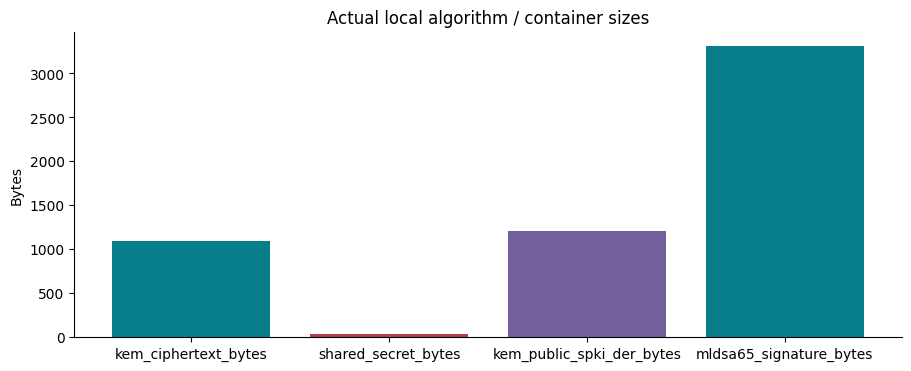

In [4]:
intermediate_tables(case)
plot_intermediate(case)

## 6. 实际运行与最终效果

模拟器使用固定种子逐次采样，counts 总数必须等于 shots。估计标准误由实际样本方差计算；近似 95% 区间可写作 estimate ± 1.96 × SE，但小样本及零计数需另用适当区间。本例不把这些区间当成硬件精度验收。

In [5]:
evidence = run_local_case(case, shots=SHOTS, seed=SEED)
show_measurements(case, evidence)

## 7. 可检查的电路输出

导出全部业务电路的 OpenQASM 2，位串采用 q0-first。可导出不等于已通过夸父设备门集、耦合图、深度和精度验收；本批不会访问凭据、提交任务或消耗金融额度。纯经典案例没有伪造量子电路。

In [6]:
for name, result in evidence['experiments'].items():
    print('\n---', name, '---\n'+result['openqasm2'])
if not evidence['experiments']:
    print('Classical cryptography / security workflow: no quantum circuit.')

Classical cryptography / security workflow: no quantum circuit.


## 8. 结果解释、复做与非目标

共享秘密一致、合法签名接受、改动消息拒绝三个条件应同时成立。KEM 密文 1088 字节、秘密 32 字节、ML-DSA-65 签名 3309 字节；后两种安全性质仍依赖标准假设与正确部署。

调用实际密码实现不等于 FIPS 140 模块认证、完整系统迁移或所有 PQC 候选支持。公钥 DER 尺寸包含容器开销；不把 SPKI 尺寸误当原始公钥长度。不包含 UOV/SNOVA 插件。

练习：对已有电路将 shots 改为 2048，比较估计与标准误；如果是纯经典密码案例，比较密文/公钥大小和篡改检测结果。安全案例的私钥只在临时目录或内存中存在，不输出密钥。重新执行此 Notebook 仍然只运行本地代码。

In [7]:
repeat = run_local_case(case, shots=2048, seed=SEED+100)
show_json({'execution_mode':repeat['execution_mode'], 'estimates':repeat['estimates'], 'new_cloud_tasks':repeat['new_cloud_tasks']})
assert all(sum(row['counts'].values()) == 2048 for row in repeat['experiments'].values())
assert repeat['new_cloud_tasks'] == 0
assert repeat['hardware_access'] is False

In [8]:
artifact = {'inputs':case.inputs, 'intermediate':case.intermediate, 'reference':case.reference, 'evidence':evidence}
path = root/'output/jupyter-notebook/security/01_pqc_evidence.json'
path.parent.mkdir(parents=True, exist_ok=True)
path.write_text(json.dumps(artifact, ensure_ascii=False, indent=2), encoding='utf-8')
print('Evidence:', path.name)

Evidence: 01_pqc_evidence.json


## 9. 参考与责任边界

独立编写应用代码，未复制上游 SDK 实现或第三方教程代码；下列资料用于数学与接口背景。

- [NIST FIPS 203：ML-KEM](https://csrc.nist.gov/pubs/fips/203/final)
- [NIST FIPS 204：ML-DSA](https://csrc.nist.gov/pubs/fips/204/final)
- [OpenSSL 3.6 pkeyutl 接口](https://docs.openssl.org/3.6/man1/openssl-pkeyutl/)

本案例不是生产支持证书，也不代表 Qiskit / PennyLane 全量替代已经完成。